# As regras de verba aguentam o ruído? Decisão de tráfego pago antes da primeira venda

**Contexto.** Este estudo nasceu do lançamento de um produto digital do autor, antes da primeira venda.
Por isso é publicado em **unidades relativas**: a meta de CAC vale 100 e todo valor em moeda é lido
contra ela. Preço, custos, verba e parâmetros do lançamento ficam num arquivo local fora do repositório;
o repositório traz um arquivo de exemplo com valores fictícios, com o qual o código roda.

Quase toda operação de tráfego pago tem uma meta de CAC e duas regras de bolso para a verba:

- **Corte:** desligar o criativo quando o gasto chega a *k* vezes a meta sem venda, ou quando o CAC passa
  de *k* vezes a meta.
- **Escala:** só subir a verba depois de *n* dias seguidos com o CAC na meta.

**Pergunta.** Antes de gastar: a conta fecha? E regras desse formato tomam a decisão certa quando os
números do dia a dia oscilam por acaso?

**O que é dado real e o que é premissa**

| Entrada | Origem |
|---|---|
| Custo variável por venda e por demonstração grátis | Medido |
| Câmbio | PTAX diária do Banco Central, últimos 12 meses |
| Taxas de pagamento e imposto | Publicadas, a confirmar |
| CPC, conversões, receita de extras, reembolso | **Premissa.** O produto ainda não tinha clientes na data da análise |
| Operação da seção 5 | **Simulada**, com valores fictícios, para exercitar a camada SQL com a verdade conhecida |

Nada aqui prevê o resultado do lançamento. O que a análise entrega é: onde a conta é sensível, o que
medir primeiro e com que frequência cada formato de regra erra.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from trafego_decisao import analise, economia, graficos, parametros, regras

pd.set_option("display.float_format", lambda v: f"{v:.2f}")


def mostrar(figura):
    display(figura)
    plt.close(figura)


p = parametros.carregar()
ptax = analise.carregar_cambio()
print(parametros.aviso_da_fonte(p))

Parâmetros: arquivo privado (valores reais). Tudo abaixo está na escala em que a meta de CAC vale 100.


## 1. A conta de uma venda

De cada venda saem a taxa de pagamento, o imposto, o custo de entrega do pedido e o custo das
**demonstrações grátis que não viraram compra**. Quem experimenta e vai embora não paga, então quem
compra carrega essa conta. O que resta é a **sobra para mídia**: o máximo que se pode pagar para trazer
um comprador.

Primeiro, a conferência: a função de margem reproduz duas contas feitas à parte?

In [2]:
analise.conferir_modelo(p).style.format("{:+.2%}")

,desvio do modelo
conta,
"Margem sem extras, só cartão, sem demonstração perdida",-0.03%
Margem com extras e demonstrações perdidas,-0.73%


Reproduz, com desvio abaixo de 1%. Com os valores-base e o dólar mais recente, a sobra para mídia é o
**CAC de empate**. Daqui em diante ele aparece na escala em que a meta de CAC vale 100:

In [3]:
equilibrio = economia.sobra_de_referencia(p, ptax)  # em moeda; só é mostrado como índice
empate = p.indice(equilibrio)
print(f"CAC de empate: {empate:.0f} (a meta de CAC é 100)")
cenarios = analise.cenarios_de_referencia(p, equilibrio)
cenarios

CAC de empate: 106 (a meta de CAC é 100)


,CAC (meta = 100),CAC ÷ CAC de empate,lucro por venda (meta = 100),custo por clique (piso da faixa = 100),conversão (teto da faixa = 100)
cenário,,,,,
Ótimo,80.00,0.75,26.09,100.00,100.00
Bom,125.00,1.18,-18.91,125.00,80.00
Médio,250.00,2.36,-143.91,187.50,60.00
Ruim,500.00,4.71,-393.91,250.00,40.00


Dos quatro cenários de mídia de referência, só o "Ótimo" dá lucro na primeira compra. O "Bom" perde 19
pontos por venda, quase um quinto da meta. E o empate de 106 já supõe a estimativa mais otimista de
receita de extras e nenhum reembolso.

## 2. A conta com incerteza

Quatro cenários escolhidos à mão escondem o tamanho do espaço. Aqui cada entrada incerta ganha uma
faixa e 100 mil cenários são sorteados dentro dessas faixas. Sem dado, todo valor da faixa é tratado
como igualmente plausível.

No gráfico, os eixos são relativos às pontas das faixas: a conversão com o teto valendo 100 e o custo
por clique com o piso valendo 100. O melhor caso dos dois é o canto inferior direito.

,valor
cenarios,100000.000
fracao_que_se_paga,0.005
fracao_com_cac_na_meta,0.020
cac_mediano,236.120
sobra_mediana,78.960
sobra_p5,33.338
sobra_p95,103.458
lucro_mediano,-160.764


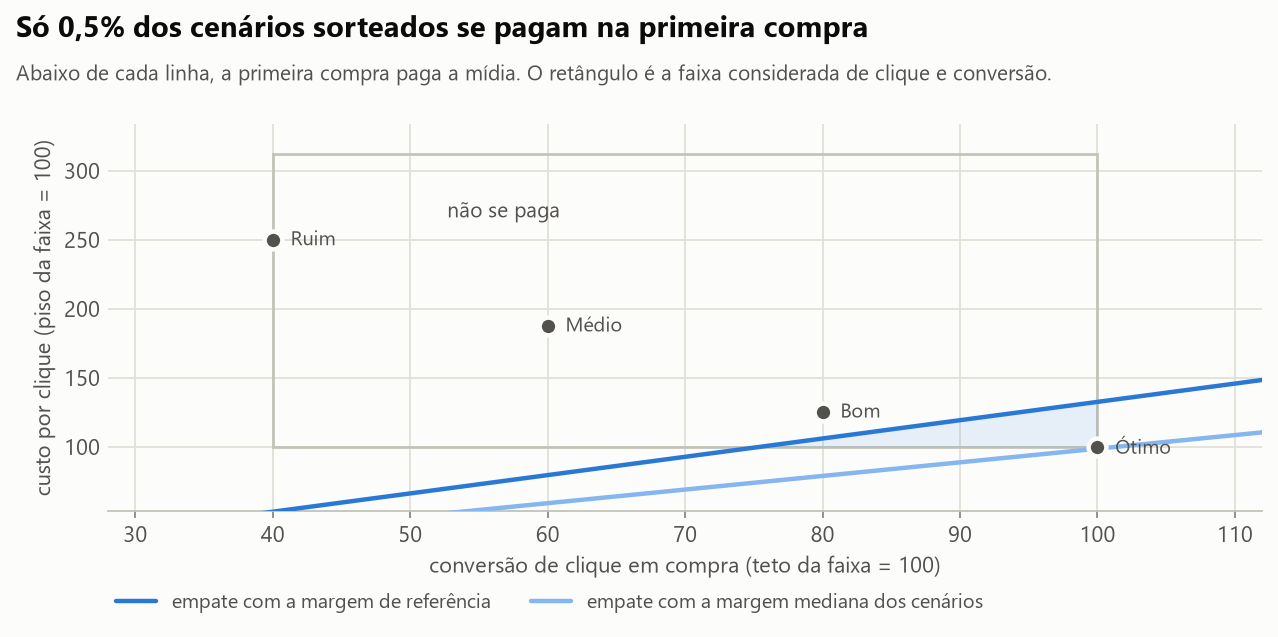

In [4]:
sorteio = economia.sortear_cenarios(p, ptax)
resumo = analise.resumo_dos_cenarios(p, sorteio)
display(pd.Series(resumo, name="valor").to_frame().style.format("{:.3f}"))
mostrar(graficos.fronteira_de_equilibrio(analise.fronteira(p, equilibrio, sorteio), cenarios, resumo["fracao_que_se_paga"]))

**Só 0,5% dos cenários se pagam na primeira compra**, e em 2% o CAC fica na meta. O gráfico mostra por
quê: dentro do retângulo de clique e conversão considerado, a região que dá lucro é um canto pequeno,
com clique perto do piso **e** conversão perto do teto.

Como ler esse número: ele não é a probabilidade de o lançamento dar certo. É o tamanho da aposta, dado
que não se sabe onde no retângulo a operação vai cair. O que ele diz com segurança é que a meta de CAC
exige o melhor caso dos dois números que mais pesam.

Quais números mais pesam? A tabela abaixo varia uma entrada de cada vez, com as outras no valor-base.

,origem,lucro no pior extremo,lucro no melhor extremo,amplitude,amplitude ÷ maior amplitude
entrada,,,,,
Custo por clique,publicado,-206.41,6.09,212.50,1.00
Conversão de clique em compra,premissa,-143.91,6.09,150.00,0.71
Demonstrações que viram compra,premissa,-85.38,-5.62,79.76,0.38
Receita de extras por pedido,premissa,-52.44,-18.91,33.53,0.16
Imposto sobre a receita,publicado,-34.28,-18.91,15.37,0.07
Pedidos reembolsados,premissa,-31.08,-18.91,12.16,0.06
Dólar efetivo,medido,-19.32,-14.71,4.61,0.02
Pedidos pagos por Pix,premissa,-18.91,-14.38,4.54,0.02


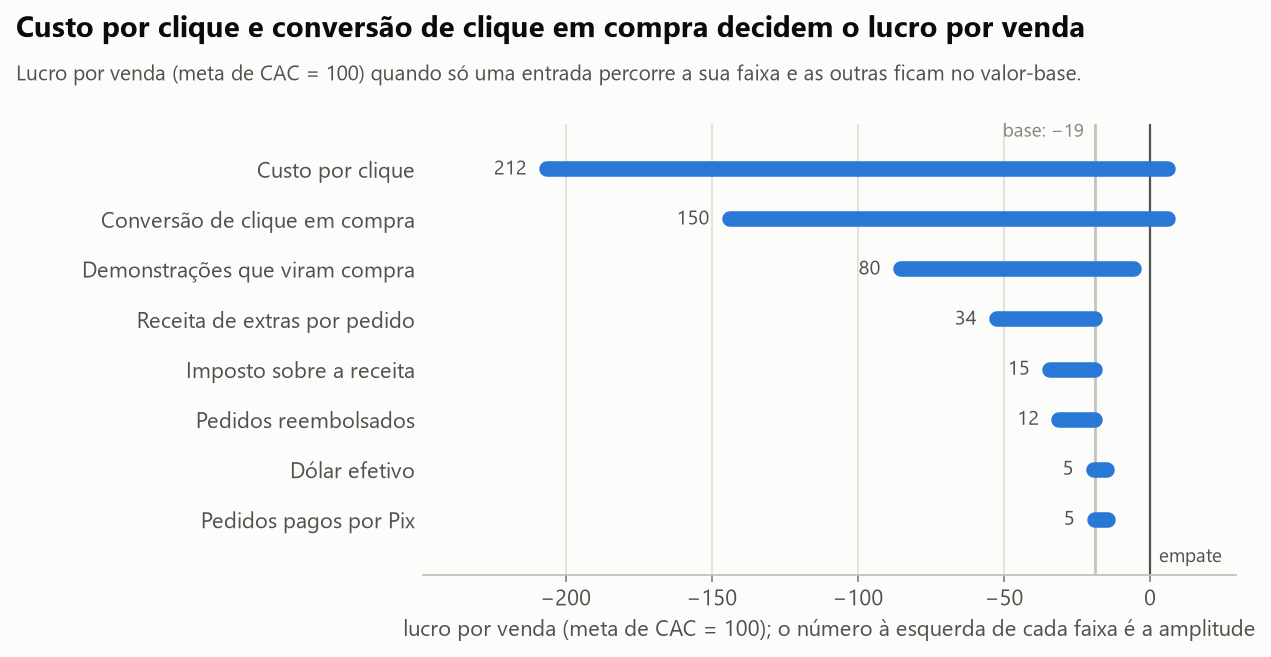

In [5]:
sensibilidade = analise.sensibilidade(p, ptax)
display(sensibilidade)
mostrar(graficos.sensibilidade(sensibilidade))

CPC e conversão movem o lucro por venda em 212 e 150 pontos. Câmbio e forma de pagamento movem 5.
Consequência prática: **o que vale medir primeiro é CPC e conversão**, e depois a fração de demonstrações
que vira compra. Negociar taxa de pagamento ou trocar de fornecedor para economizar centavos não muda a
decisão.

E quanto tempo de teste é preciso para o CAC observado deixar de ser palpite? O tamanho do teste, em
vendas esperadas, e a faixa de 90% do CAC observado numa operação que está exatamente na meta:

In [6]:
desenho = analise.desenho_do_teste(p)
display(pd.Series(desenho, name="valor").to_frame())
analise.precisao_do_cac(p, [3, 5, 7, 14])

,valor
dias de teste,14.00
"vendas esperadas por dia e por criativo, na meta",0.83
"vendas esperadas por dia na conta, na meta",12.50


,vendas esperadas,CAC observado mínimo,CAC observado máximo
dias,,,
3,37.50,78.12,133.93
5,62.50,82.24,125.00
7,87.50,84.95,121.53
14,175.00,88.83,113.64


Depois de 3 dias, uma operação com CAC real de 100 pode aparecer como 78 ou como 134, só por acaso.
Depois de 14 dias a faixa ainda vai de 89 a 114. É nesse ruído que as regras de verba precisam decidir.

## 3. A regra de corte de criativo

O número de vendas de um criativo num dia é uma contagem que oscila em torno de gasto ÷ CAC real
(distribuição de Poisson). A regra lê o CAC *observado* para adivinhar o *real*. Para saber com que
frequência ela erra, cada regra é simulada 20 mil vezes para cada CAC real possível, num teste de 14 dias
em que um criativo na meta rende 0,83 venda por dia.

Três regras:

- **Limiar simples:** desligar quando o gasto chega a *k* vezes a meta sem venda, ou quando o CAC
  acumulado passa de *k* vezes a meta, conferido ao fim de cada dia. O ponto de referência usa os
  multiplicadores mais comuns nesse tipo de regra de bolso: 2 e 1,5. Os dois são varridos mais abaixo.
- **Limiar com piso de gasto:** a mesma regra, mas o CAC só é julgado depois de o criativo ter gasto 4
  vezes a meta.
- **Teste estatístico:** desligar quando vender tão pouco seria improvável (menos de 10%) se o criativo
  estivesse no CAC de empate.

,Limiar simples,Limiar com piso de gasto,Teste estatístico
CAC real (meta = 100),,,
70,33%,12%,5%
100,59%,38%,19%
150,84%,75%,51%
200,95%,91%,76%
300,99%,99%,94%


,Limiar simples,Limiar com piso de gasto,Teste estatístico
CAC real (meta = 100),,,
70,852,1078,1128
100,634,902,1038
150,422,645,846
200,320,499,679
300,258,382,490


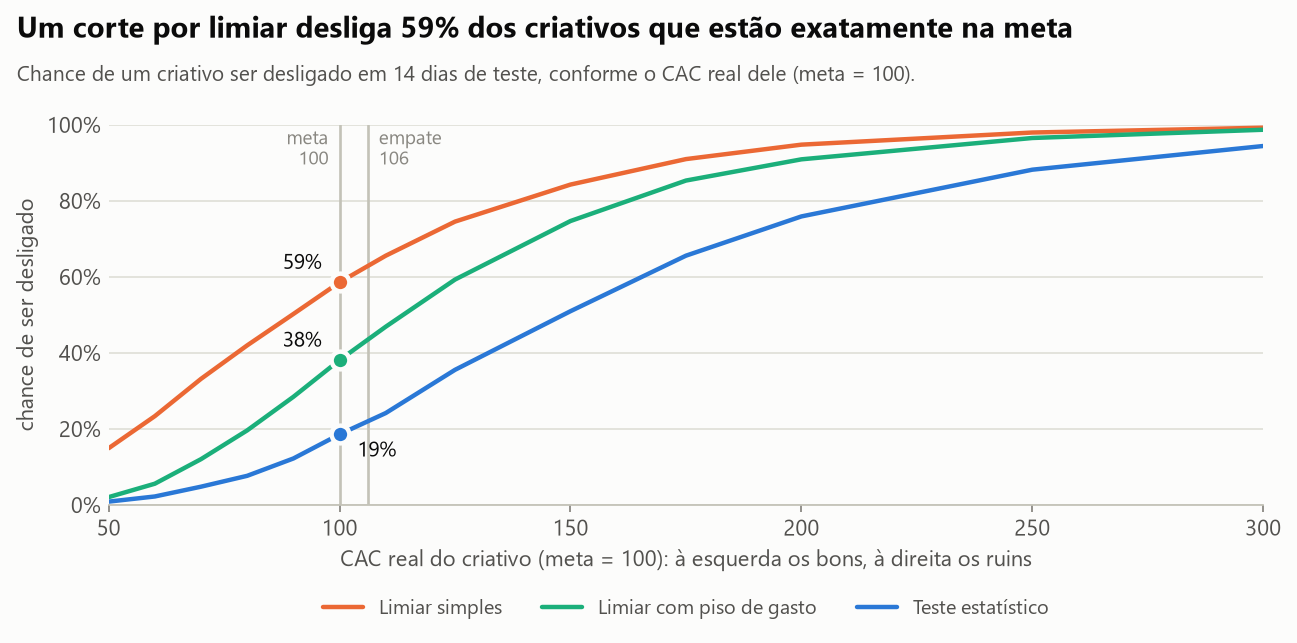

In [7]:
corte_prob, corte_gasto = analise.curvas_de_corte(p, equilibrio)
linhas = [70, 100, 150, 200, 300]
display(corte_prob.loc[linhas].style.format("{:.0%}").set_caption("Chance de ser desligado, por CAC real (meta = 100)"))
display(corte_gasto.loc[linhas].style.format("{:.0f}").set_caption("Gasto médio no criativo durante o teste (meta = 100)"))
mostrar(graficos.curvas_de_corte(corte_prob, empate, desenho))

**O limiar simples desliga 59% dos criativos que estão exatamente na meta** e um terço dos que têm CAC
real de 70, que seriam os melhores da conta. O motivo é a cláusula de CAC aplicada cedo demais: um
criativo que faz a primeira venda depois de gastar 170 tem "CAC de 170" e é desligado, embora uma venda
só não diga quase nada.

Exigir um piso de gasto antes de julgar o CAC derruba esse erro de 59% para 38% na meta e de 33% para
12% no criativo de CAC 70. O custo é deixar o criativo ruim rodar um pouco mais: um criativo com CAC real
de 200 consome em média 499 em vez de 320 antes de sair.

O teste estatístico protege ainda mais os bons (19% na meta), mas mantém os ruins por mais tempo (679 no
criativo de CAC 200). E um aviso sobre ele: como é conferido todo dia, um criativo com CAC real de 110,
logo acima do empate, é desligado em 24% das vezes, não nos 10% nominais. Olhar o mesmo teste várias
vezes infla o erro.

A escolha entre as três depende de quanto vale um criativo bom. Quando o criativo é barato de testar e a
verba de escala é muito maior que a de teste, perder um criativo bom custa muito mais que gastar 179 a
mais num ruim.

### Os multiplicadores mudam a conclusão?

A primeira tabela varre os dois multiplicadores do limiar simples e mostra a fração de criativos na meta
que a regra desliga. A segunda varre o piso de gasto, com os multiplicadores no ponto de referência.

In [8]:
grade = analise.sensibilidade_do_corte(p)
display(grade.style.format("{:.0%}").set_caption("Criativos na meta desligados. Linhas: gasto sem venda que desliga (× meta). Colunas: CAC que desliga (× meta)"))
piso = analise.sensibilidade_do_piso(p)
display(piso.style.format({piso.columns[0]: "{:.0%}", piso.columns[1]: "{:.0%}", piso.columns[2]: "{:.0f}"}).set_caption("Efeito do piso de gasto (× meta); 0 = sem piso"))

k_cac,1.250000,1.500000,2.000000,3.000000
k_sem_venda,,,,
1.500000,68%,61%,39%,25%
2.000000,66%,59%,36%,18%
3.000000,66%,58%,35%,16%
4.000000,66%,58%,34%,15%


,desliga criativo na meta,desliga criativo com o dobro da meta,gasto médio no criativo com o dobro da meta (meta = 100)
k_piso,,,
0.000000,59%,95%,320
2.000000,48%,93%,389
3.000000,45%,92%,430
4.000000,38%,91%,499
6.000000,31%,89%,634
8.000000,27%,87%,723


Quem manda é o limiar de CAC, não o de gasto sem venda: esperar mais antes de desistir de quem ainda não
vendeu quase não muda o erro (a coluna de 1,5 vai de 61% a 58%), e só um limiar de CAC bem folgado o
reduz. O piso de gasto ataca a causa, que é julgar o CAC com uma ou duas vendas: cada degrau de piso
salva criativos bons e custa gasto nos ruins, e a segunda tabela é a conta dessa troca.

## 4. A regra de escala

A mesma simulação, agora para a conta inteira, num teste de 14 dias que rende 12,5 vendas por dia na
meta. Três regras:

- **Dias seguidos na meta:** o CAC do dia na meta por *n* dias seguidos. Ponto de referência: *n* = 5.
- **Qualquer janela de *n* dias:** o CAC somado de alguma sequência de *n* dias na meta.
- **Período inteiro:** o CAC somado do teste inteiro na meta, olhado uma vez só, no fim.

,retorno sobre a verba de escala,Dias seguidos na meta (n = 5),Qualquer janela de n dias na meta (n = 5),Período inteiro na meta
CAC real (meta = 100),,,,
80,+33%,76%,100%,100%
90,+18%,42%,100%,93%
100,+6%,14%,93%,51%
110,-4%,4%,66%,11%
120,-12%,1%,33%,1%
130,-18%,0%,12%,0%


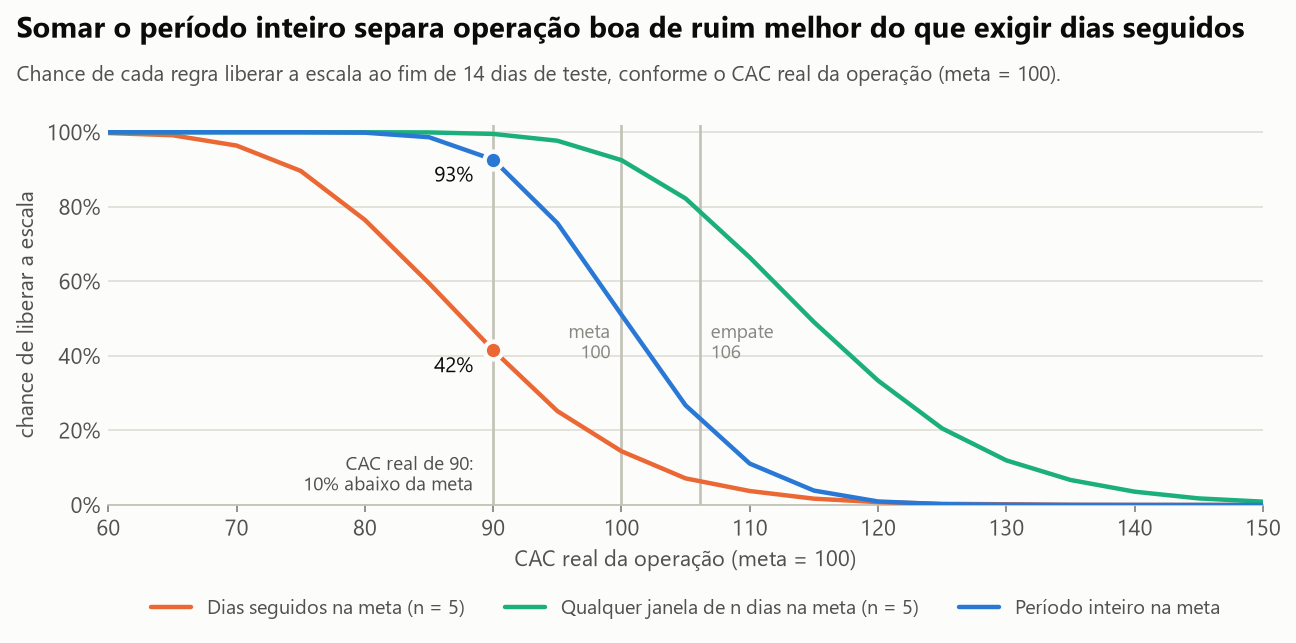

In [9]:
escala = analise.curvas_de_escala(p)
consequencia = analise.consequencia_da_escala(p, escala, equilibrio)
formatos = {"retorno sobre a verba de escala": "{:+.0%}"} | {c: "{:.0%}" for c in escala.columns}
display(consequencia.style.format(formatos))
mostrar(graficos.curvas_de_escala(escala, empate, desenho))

A coluna "retorno sobre a verba de escala" é o lucro de escalar com aquele CAC real, dividido pela verba
de mídia: positivo abaixo do CAC de empate, negativo acima.

- **Exigir dias seguidos é seguro, mas perde operação boa.** Com CAC real de 90, que devolve 18% sobre a
  verba, a regra só libera em 42% das vezes. Um dia ruim no meio da sequência zera a contagem, e a regra
  descarta a informação dos outros dias.
- **"Qualquer janela" é permissiva demais.** Libera 66% das vezes uma operação de CAC 110, que dá
  prejuízo. Há dez janelas possíveis em 14 dias, e basta uma dar sorte.
- **Somar o período inteiro é a mais nítida.** Libera 93% das vezes a operação de CAC 90 e 1% das vezes
  a de CAC 120, igual à regra dos dias seguidos. O preço é liberar 11% das vezes uma operação de CAC
  110, contra 4%.

E um resultado útil: um teste estatístico formal vira uma regra de uma linha. O teste "há menos de 10% de
chance de ver tantas vendas se o CAC real fosse o de empate" equivale a um limite de CAC acumulado, e a
regra simples de "CAC do período na meta" é uma versão um pouco mais permissiva dele:

In [10]:
pd.Series(analise.limites_estatisticos(p, equilibrio), name="CAC acumulado máximo para liberar a escala (meta = 100)").to_frame()

,CAC acumulado máximo para liberar a escala (meta = 100)
7 dias,92.11
14 dias,95.63


Ou seja: quem quiser decidir na metade do teste precisa de um limite mais apertado (92 em vez de 96),
porque há menos dado.

### E com outro *n*?

Chance de liberar uma operação boa (CAC 90) e uma ruim (CAC 110), para cada *n*:

In [11]:
analise.sensibilidade_da_escala(p).style.format("{:.0%}")

,dias seguidos: libera a boa (CAC 90),dias seguidos: libera a ruim (CAC 110),qualquer janela: libera a boa (CAC 90),qualquer janela: libera a ruim (CAC 110)
n,,,,
2,99%,75%,100%,98%
3,87%,32%,100%,88%
4,64%,11%,100%,81%
5,42%,4%,100%,66%
6,25%,1%,99%,59%
7,15%,0%,99%,47%


Nenhum *n* resolve. Com *n* pequeno a regra dos dias seguidos libera a operação boa, mas libera a ruim
junto (*n* = 3: 87% e 32%). Com *n* grande ela barra a ruim e barra a boa. O período inteiro libera a boa
em 93% das vezes e a ruim em 11%: é o erro que os dias seguidos só alcançam com *n* = 4, quando liberam
a boa em 64%. A janela móvel é permissiva para qualquer *n*.

### E se o dia a dia for mais irregular que o acaso puro?

Leilão, dia da semana e criativo cansando fazem as vendas oscilarem mais do que o Poisson supõe. Repetindo
a simulação com o dobro da variância:

In [12]:
irregular = analise.curvas_de_escala(p, dispersao=2.0).loc[[80, 90, 100, 110, 120, 130]]
display(irregular.style.format("{:.0%}").set_caption("Chance de liberar a escala, com vendas duas vezes mais irregulares"))
corte_irregular, _ = analise.curvas_de_corte(p, equilibrio, dispersao=2.0)
display(corte_irregular.loc[[70, 100, 200]].style.format("{:.0%}").set_caption("Chance de corte, com vendas duas vezes mais irregulares"))

,Dias seguidos na meta (n = 5),Qualquer janela de n dias na meta (n = 5),Período inteiro na meta
CAC real (meta = 100),,,
80,55%,100%,99%
90,28%,99%,84%
100,12%,92%,50%
110,5%,75%,19%
120,2%,52%,5%
130,0%,32%,1%


,Limiar simples,Limiar com piso de gasto,Teste estatístico
CAC real (meta = 100),,,
70,45%,26%,14%
100,67%,53%,36%
200,93%,90%,81%


A ordem entre as regras não muda, mas todos os erros crescem: a regra do período inteiro passa a liberar
19% das vezes a operação de CAC 110 e 5% a de CAC 120. As taxas de erro deste notebook são, portanto, o
melhor caso. A dispersão real só se mede com dados da operação.

## 5. A camada de métricas em SQL

As regras só funcionam se alguém calcular o CAC do jeito certo todo dia. As consultas em `sql/` fazem
isso no DuckDB, sobre três tabelas: gasto de mídia, demonstrações e pagamentos.

| Consulta | O que faz | Técnica |
|---|---|---|
| `metricas_diarias.sql` | Funil e CAC por dia e criativo | CTEs, `LEFT JOIN`, `FILTER` |
| `corte_criativos.sql` | Primeiro dia em que cada regra de corte dispara | Soma acumulada com janela |
| `escala_dias_seguidos.sql` | Dias seguidos na meta e CAC acumulado | Ilhas e lacunas com `ROW_NUMBER` |
| `margem_por_criativo.sql` | Resultado por criativo, com demonstrações perdidas | Agregação condicional |

Como ainda não há venda, as consultas rodam sobre **uma operação simulada** de 14 dias com 9 criativos,
com valores fictícios na mesma escala (meta = 100) e o CAC real de cada criativo conhecido. Os testes do
projeto conferem que o SQL e as regras em Python chegam à mesma decisão sobre os mesmos dados.

In [13]:
operacao = analise.operacao_simulada()
operacao["corte"]

,criativo,cac_real,corte_limiar_simples,corte_limiar_com_piso,gasto_no_teste,vendas_no_teste,cac_no_teste
0,C1,110.00,NaT,NaT,1166.67,15.00,77.78
1,A1,70.00,2030-01-08,NaT,1166.67,12.00,97.22
2,A2,100.00,NaT,NaT,1166.67,12.00,97.22
3,B1,90.00,2030-01-09,2030-01-09,1166.67,11.00,106.06
4,B2,130.00,2030-01-08,2030-01-11,1166.67,9.00,129.63
5,C2,200.00,2030-01-12,2030-01-12,1166.67,9.00,129.63
6,A3,160.00,NaT,NaT,1166.67,8.00,145.83
7,B3,275.00,2030-01-08,2030-01-17,1166.67,8.00,145.83
8,C3,400.00,2030-01-09,2030-01-09,1166.67,4.00,291.67


Um sorteio só, mas ele mostra o problema da seção 3 acontecendo: `A1`, o melhor criativo da conta (CAC
real de 70), é desligado pelo limiar simples no segundo dia. `A3`, com CAC real de 160, sobrevive ao
teste inteiro. Na vida real ninguém vê a coluna `cac_real`; só se vê o CAC do teste, que nos dois casos
engana.

In [14]:
operacao["escala"]

,dia,gasto,vendas,cac_dia,na_meta,dias_seguidos_na_meta,libera_escala,cac_acumulado
0,2030-01-07,750.00,5.00,150.00,False,0,False,150.00
1,2030-01-08,750.00,6.00,125.00,False,0,False,136.36
2,2030-01-09,750.00,4.00,187.50,False,0,False,150.00
3,2030-01-10,750.00,11.00,68.18,True,1,False,115.38
4,2030-01-11,750.00,5.00,150.00,False,0,False,120.97
5,2030-01-12,750.00,8.00,93.75,True,1,False,115.38
6,2030-01-13,750.00,5.00,150.00,False,0,False,119.32
7,2030-01-14,750.00,11.00,68.18,True,1,False,109.09
8,2030-01-15,750.00,7.00,107.14,False,0,False,108.87
9,2030-01-16,750.00,2.00,375.00,False,0,False,117.19


In [15]:
operacao["margem"]

,criativo,cac_real,cliques,demonstracoes,pedidos,taxa_demo_venda,midia,cac,receita,sobra_antes_da_midia,resultado
0,C1,110.00,189.00,82.00,15,0.18,1166.67,77.78,2080.00,1375.90,209.23
1,A2,100.00,186.00,64.00,12,0.19,1166.67,97.22,1580.00,1034.10,-132.57
2,A1,70.00,208.00,110.00,12,0.11,1166.67,97.22,1790.00,1004.30,-162.37
3,B2,130.00,205.00,60.00,9,0.15,1166.67,129.63,1430.00,931.00,-235.67
4,C2,200.00,192.00,42.00,9,0.21,1166.67,129.63,1150.00,776.00,-390.67
5,A3,160.00,194.00,50.00,8,0.16,1166.67,145.83,1170.00,756.10,-410.57
6,B3,275.00,213.00,41.00,8,0.20,1166.67,145.83,1030.00,683.50,-483.17
7,B1,90.00,192.00,80.00,11,0.14,1166.67,106.06,1270.00,676.90,-489.77
8,C3,400.00,207.00,23.00,4,0.17,1166.67,291.67,550.00,363.90,-802.77


## Conclusões

1. **A meta de CAC exige o melhor caso.** A sobra por venda para pagar mídia é 106, só 6% acima da
   meta de CAC, no melhor caso de extras. Dentro das faixas consideradas, 0,5% dos cenários se pagam na
   primeira compra. Dos quatro cenários de referência, só o "Ótimo" dá lucro.
2. **O que medir primeiro:** CPC e conversão de clique em compra, depois a fração de demonstrações que
   vira compra. Juntos explicam quase toda a variação do resultado.
3. **Corte por limiar desliga criativo bom.** 59% dos que estão na meta, no ponto de referência. Mexer nos
   multiplicadores ajuda pouco; exigir um piso de gasto antes de julgar o CAC reduz isso para 38%, ao
   custo de 179 a mais por criativo ruim.
4. **Exigir dias seguidos na meta perde operação boa.** Com CAC real 10% abaixo da meta, só libera em 42%
   das vezes, e nenhum *n* conserta. Olhar o CAC somado do período inteiro libera em 93%.

## Limitações

- **Nenhuma venda real.** CPC, conversões, receita de extras e reembolso são premissas. As conclusões 1
  e 2 dependem das faixas escolhidas.
- **Só a primeira compra.** O modelo não conta recompra, indicação, tráfego orgânico nem a recuperação
  de quem deixou contato e não comprou. Tudo isso melhora a conta, e nada disso tem dado ainda.
- **Sorteio uniforme.** Tratar toda a faixa como igualmente plausível é a escolha de quem não tem dado.
  Com uma semana de operação, as faixas de CPC e conversão encolhem e a análise deve ser refeita.
- **Vendas como Poisson.** As taxas de erro das regras são o melhor caso; com dias mais irregulares os
  erros crescem (seção 4).
- **Momento da conferência.** As regras de corte são conferidas ao fim de cada dia, desde a primeira
  venda. Conferir com outra frequência muda as taxas.
- **O tamanho do teste importa.** As taxas valem para o volume de vendas esperado deste teste. Com mais
  volume por criativo, todas as regras erram menos.
- **Unidades relativas.** Os números deste notebook foram gerados com os parâmetros reais, que não estão
  no repositório. Com o arquivo de exemplo o código roda de ponta a ponta, mas os valores são outros.